# Clasificación de compuertas lógicas dibujadas a mano con redes neuronales

**PC2 · Computación Gráfica · UNI**

**Objetivo:** reconocer qué compuerta lógica se dibujó a mano (AND, OR, NOT, NAND, NOR o XOR) y comparar tres redes vistas en el curso.

| Modelo | Tema del curso | Idea |
|---|---|---|
| 1. Perceptrón multicapa (MLP) | Clase 1: perceptrón, problema del XOR, capas ocultas | Ve la imagen como una lista de píxeles |
| 2. Red convolucional (CNN) | Clase 1: LeNet y el código Keras de la clase · Clase 2: aritmética de la convolución | Filtros que recorren la imagen y detectan formas locales |
| 3. CNN con Global Average Pooling y CAM | Clase 3: GAP y Class Activation Maps | Menos parámetros y un mapa de dónde mira la red |

**Contenido**
1. Carga de datos
2. Preprocesamiento
3. Exploración del dataset
4. División en entrenamiento, validación y prueba
5. Aumento de datos
6. Modelo 1: perceptrón multicapa (MLP)
7. Modelo 2: red convolucional (CNN)
8. Modelo 3: CNN con Global Average Pooling
9. Métricas: accuracy, precisión, recall, F1 y matriz de confusión
10. Parejas difíciles y errores
11. Class Activation Maps (CAM)
12. Resumen y conclusiones

Cada modelo se entrena 10 épocas. El notebook corre en Google Colab con o sin GPU.

## 1. Carga de datos

Los dibujos se recolectaron con la página web del repositorio (lienzo de 256×256). Cada PNG está en una carpeta con el nombre de su compuerta y el trazo va en el canal alfa (transparencia). El archivo `dataset.zip` del repositorio también trae una carpeta `OTRO` (dibujos que no son compuertas); en este notebook **no se usa**, solo se cargan las 6 compuertas.

Si `dataset.zip` no está en la carpeta actual (por ejemplo, en Colab), se descarga del repositorio.

In [1]:
import os, zipfile, urllib.request, collections
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

URL_DATASET = "https://github.com/Faalvial/compuertas_logicas/raw/main/dataset.zip"
RUTA_ZIP = "dataset.zip"
CARPETA = "dataset"
CLASES = ["AND", "OR", "NOT", "NAND", "NOR", "XOR"]

if not os.path.exists(RUTA_ZIP):
    print("Descargando", URL_DATASET)
    urllib.request.urlretrieve(URL_DATASET, RUTA_ZIP)

with zipfile.ZipFile(RUTA_ZIP) as zf:
    zf.extractall(CARPETA)
print("Dataset extraído en", CARPETA)

Descargando https://github.com/Faalvial/compuertas_logicas/raw/main/dataset.zip
Dataset extraído en dataset


## 2. Preprocesamiento

Cada dibujo pasa por estos pasos:
1. **Canal alfa:** el lienzo es transparente y el trazo opaco, así que el canal alfa ya es una imagen en escala de grises (0 = fondo, 255 = tinta).
2. **Recorte:** se recorta al rectángulo que contiene la tinta. Así no importa en qué parte del lienzo ni de qué tamaño se dibujó.
3. **Cuadrado con margen:** se centra en un cuadrado con 8% de margen por lado, para no deformar la compuerta.
4. **Redimensionar y normalizar:** se reduce a 64×64 píxeles y se divide entre 255 (valores entre 0 y 1).

In [2]:
TAM = 64
MARGEN = 0.08

def recortar_cuadrado(ruta, margen=MARGEN):
    alfa = Image.open(ruta).convert("RGBA").getchannel("A")
    caja = alfa.getbbox()                     # rectángulo con tinta
    if caja is None:
        return None
    x0, y0, x1, y1 = caja
    lado = int(max(x1 - x0, y1 - y0) * (1 + 2 * margen))
    cuadrado = Image.new("L", (lado, lado), 0)
    cuadrado.paste(alfa.crop(caja), ((lado - (x1 - x0)) // 2, (lado - (y1 - y0)) // 2))
    return cuadrado.resize((TAM, TAM), Image.Resampling.LANCZOS)

imagenes, etiquetas, autores = [], [], []
for i, clase in enumerate(CLASES):
    carpeta = os.path.join(CARPETA, clase)
    for nombre in sorted(os.listdir(carpeta)):
        if not nombre.endswith(".png"):
            continue
        img = recortar_cuadrado(os.path.join(carpeta, nombre))
        if img is None:
            continue
        imagenes.append(np.asarray(img, dtype=np.float32) / 255.0)
        etiquetas.append(i)
        partes = nombre.split("_")                       # <fecha>_<autor>_<id>.png
        autores.append(partes[1] if len(partes) >= 3 else "sin nombre")

X = np.stack(imagenes)
y = np.array(etiquetas)
print("Imágenes:", X.shape, " Etiquetas:", y.shape)

Imágenes: (3000, 64, 64)  Etiquetas: (3000,)


## 3. Exploración del dataset

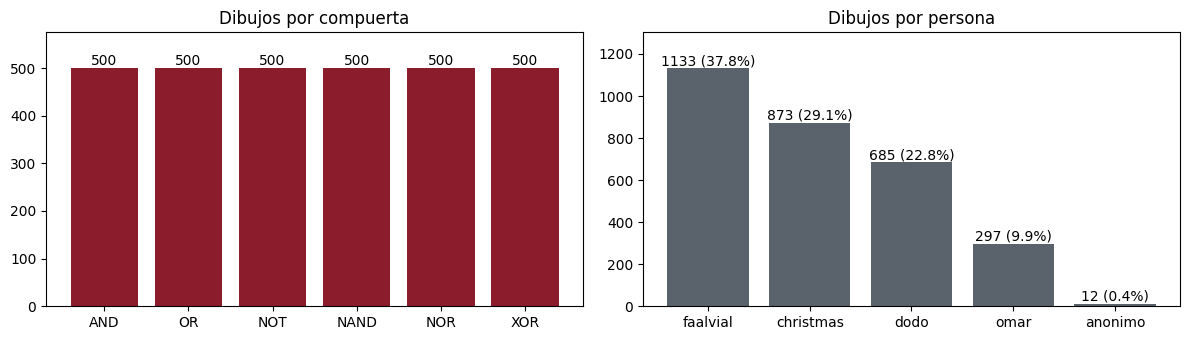

{'AND': 500, 'OR': 500, 'NOT': 500, 'NAND': 500, 'NOR': 500, 'XOR': 500}  total: 3000


In [3]:
conteo = np.bincount(y, minlength=len(CLASES))
por_autor = collections.Counter(autores)
nombres = [a for a, _ in por_autor.most_common()]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(CLASES, conteo, color="#8a1c2b")
ax[0].set_title("Dibujos por compuerta")
for i, n in enumerate(conteo):
    ax[0].text(i, n, str(n), ha="center", va="bottom")
ax[0].set_ylim(0, conteo.max() * 1.15)
ax[1].bar(nombres, [por_autor[a] for a in nombres], color="#5a626c")
ax[1].set_title("Dibujos por persona")
for i, a in enumerate(nombres):
    ax[1].text(i, por_autor[a], f"{por_autor[a]} ({por_autor[a] / len(y):.1%})", ha="center", va="bottom")
ax[1].set_ylim(0, max(por_autor.values()) * 1.15)
plt.tight_layout(); plt.show()
print(dict(zip(CLASES, conteo.tolist())), " total:", conteo.sum())

Los dibujos marcados como «sin nombre» también son del equipo: se enviaron sin escribir el nombre en la página.

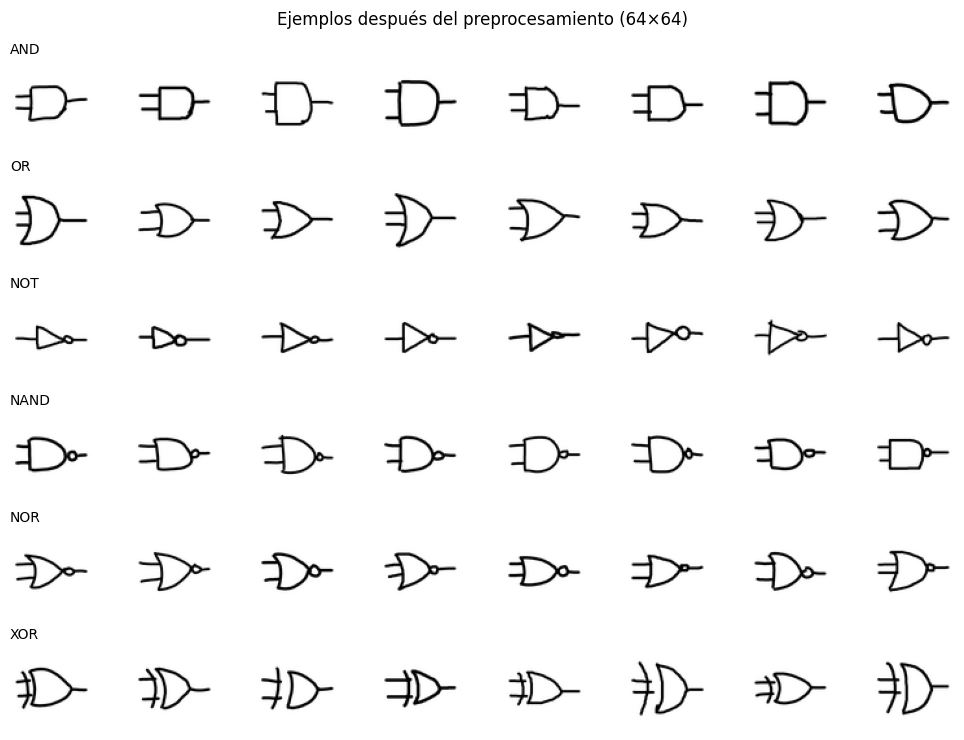

In [4]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(CLASES), 8, figsize=(10, 7.5))
for i, clase in enumerate(CLASES):
    idx = rng.choice(np.where(y == i)[0], size=8, replace=False)
    for j in range(8):
        axes[i, j].imshow(X[idx[j]], cmap="gray_r"); axes[i, j].axis("off")
    axes[i, 0].set_title(clase, loc="left", fontsize=10)
plt.suptitle(f"Ejemplos después del preprocesamiento ({TAM}×{TAM})"); plt.tight_layout(); plt.show()

La **imagen promedio** de cada compuerta muestra qué tan parecidos son los dibujos entre sí. En NAND y NOR se ve la burbuja a la derecha, y en XOR el arco extra a la izquierda.

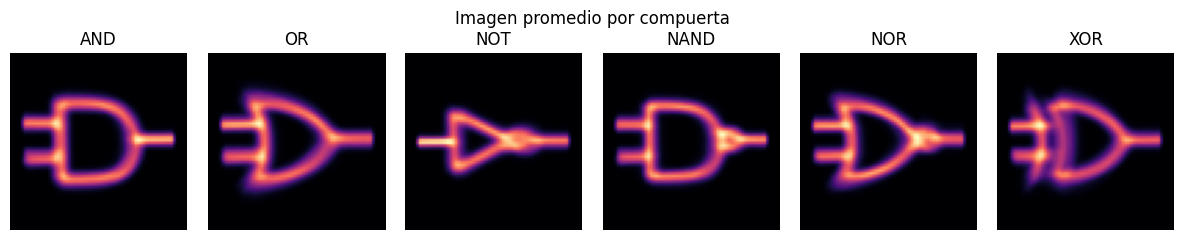

In [5]:
fig, axes = plt.subplots(1, len(CLASES), figsize=(12, 2.4))
for i, clase in enumerate(CLASES):
    axes[i].imshow(X[y == i].mean(axis=0), cmap="magma"); axes[i].set_title(clase); axes[i].axis("off")
plt.suptitle("Imagen promedio por compuerta"); plt.tight_layout(); plt.show()

## 4. División en entrenamiento, validación y prueba

- **Entrenamiento (70%):** la red ajusta sus pesos con estos dibujos.
- **Validación (15%):** se mide al final de cada época para ver si la red está memorizando (sobreajuste).
- **Prueba (15%):** solo se usa al final, para medir el resultado con dibujos que la red nunca vio.

La división es **estratificada** (cada conjunto tiene la misma proporción de cada compuerta) y usa una semilla fija para que se pueda repetir.

In [6]:
from sklearn.model_selection import train_test_split
import keras
from keras import layers

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

indices = np.arange(len(y))
idx_train, idx_tmp = train_test_split(indices, test_size=0.30, stratify=y, random_state=SEMILLA)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEMILLA)

X4 = X[..., None]                       # un canal (escala de grises): (n, 64, 64, 1)
X_train, X_val, X_test = X4[idx_train], X4[idx_val], X4[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]
print("Entrenamiento:", X_train.shape, " Validación:", X_val.shape, " Prueba:", X_test.shape)

Entrenamiento: (2100, 64, 64, 1)  Validación: (450, 64, 64, 1)  Prueba: (450, 64, 64, 1)


## 5. Aumento de datos

Con unos 2100 dibujos de entrenamiento, la red podría aprenderse los dibujos de memoria en lugar de la forma de cada compuerta. El **aumento de datos** cambia un poco cada dibujo al azar en cada época, así la red casi nunca ve dos veces la misma imagen. Imita la variación natural entre personas:

| Transformación | Cuánto | Por qué |
|---|---|---|
| Giro | ±15° | Nadie dibuja perfectamente horizontal |
| Desplazamiento | ±10% (unos 6 píxeles) | El recorte no siempre queda igual de centrado |
| Zoom | ±10% | Trazos más o menos largos |
| Volteo vertical (arriba ↔ abajo) | 50% de las veces | Las 6 compuertas son simétricas de arriba abajo: un AND volteado sigue siendo AND |

**No** se usa volteo horizontal: una compuerta volteada de izquierda a derecha tendría la salida a la izquierda, que no es un dibujo válido.

Las capas de aumento solo actúan al entrenar; al predecir dejan pasar la imagen sin cambios. Se aplican a las dos CNN (modelos 2 y 3). El MLP es el modelo base y se entrena sin ellas. Para entrenar las CNN sin aumento, basta poner `USAR_AUMENTO = False`.

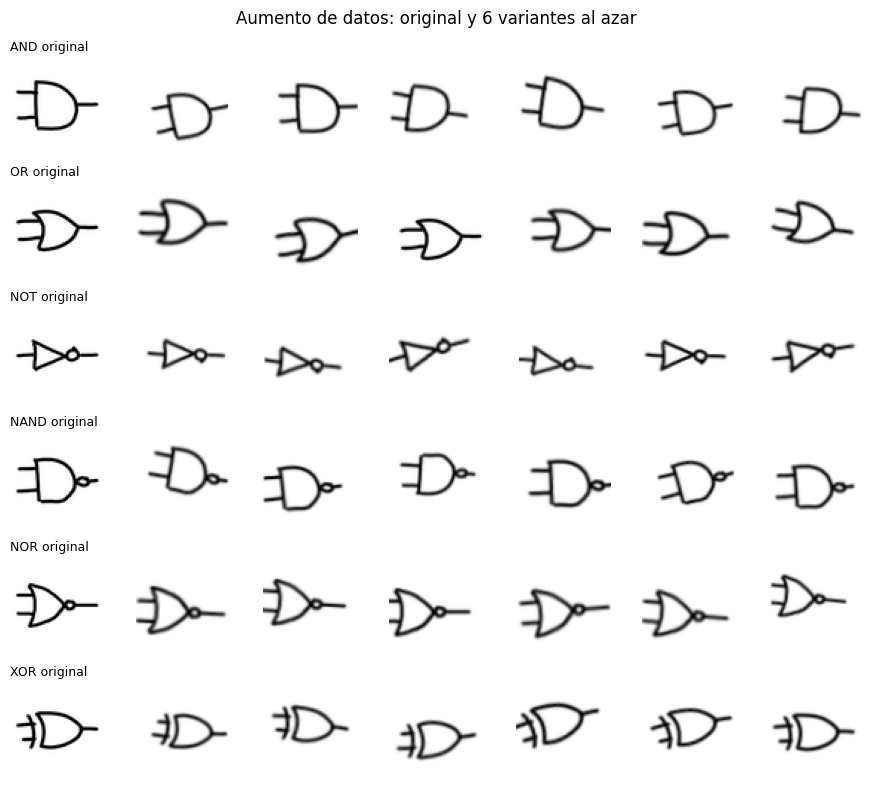

In [7]:
USAR_AUMENTO = True
GIRO_GRADOS = 15

def capas_aumento_de_datos():
    # Una copia nueva para cada modelo que la use.
    return keras.Sequential([
        layers.RandomRotation(GIRO_GRADOS / 360, fill_mode="constant"),   # el factor es una fracción de vuelta
        layers.RandomTranslation(0.10, 0.10, fill_mode="constant"),
        layers.RandomZoom(0.10, fill_mode="constant"),
        layers.RandomFlip("vertical"),
    ], name="aumento_de_datos")

# Ejemplo: un dibujo de cada compuerta y 6 versiones aumentadas
aumento = capas_aumento_de_datos()
fig, axes = plt.subplots(len(CLASES), 7, figsize=(9, 8))
for i, clase in enumerate(CLASES):
    original = X_train[np.where(y_train == i)[0][0]]
    axes[i, 0].imshow(original[..., 0], cmap="gray_r")
    for j in range(1, 7):
        axes[i, j].imshow(aumento(original[None], training=True)[0, ..., 0], cmap="gray_r")
    for a in axes[i]:
        a.axis("off")
    axes[i, 0].set_title(f"{clase} original", loc="left", fontsize=9)
plt.suptitle("Aumento de datos: original y 6 variantes al azar"); plt.tight_layout(); plt.show()

## 6. Modelo 1: perceptrón multicapa (MLP)

**Clase 1.** Un perceptrón de una capa solo puede separar clases con una recta (un hiperplano); por eso no puede calcular XOR (Minsky y Papert, 1969). La solución es agregar una **capa oculta**: eso es un perceptrón multicapa.

Este MLP aplana la imagen de 64×64 en un vector de 4096 píxeles, la pasa por una capa oculta de 128 neuronas con ReLU y termina en 6 neuronas con softmax (una probabilidad por compuerta). No sabe qué píxeles están al lado de cuáles: ve la imagen como una lista.

Todos los modelos se entrenan igual:
- **Pérdida:** entropía cruzada, `sparse_categorical_crossentropy` (las etiquetas son números del 0 al 5).
- **Optimizador:** Adam, con su tasa de aprendizaje por defecto (0.001).
- **10 épocas** en lotes de 64 dibujos. Una época es una pasada por todos los dibujos de entrenamiento.

In [8]:
EPOCAS = 10
LOTE = 64

def entrenar(modelo):
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    modelo.summary()
    return modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=EPOCAS, batch_size=LOTE, verbose=2)

mlp = keras.Sequential([
    keras.Input((TAM, TAM, 1)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(CLASES), activation="softmax"),
], name="MLP")
hist_mlp = entrenar(mlp)

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 525,190 (2.00 MB)

 Trainable params: 525,190 (2.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
33/33 - 2s - 49ms/step - accuracy: 0.7719 - loss: 0.6398 - val_accuracy: 0.9000 - val_loss: 0.3107
Epoch 2/10
33/33 - 0s - 13ms/step - accuracy: 0.9381 - loss: 0.2091 - val_accuracy: 0.9467 - val_loss: 0.1741
Epoch 3/10
33/33 - 0s - 12ms/step - accuracy: 0.9790 - loss: 0.1073 - val_accuracy: 0.9689 - val_loss: 0.1268
Epoch 4/10
33/33 - 0s - 12ms/step - accuracy: 0.9914 - loss: 0.0620 - val_accuracy: 0.9711 - val_loss: 0.1004
Epoch 5/10
33/33 - 0s - 12ms/step - accuracy: 0.9971 - loss: 0.0402 - val_accuracy: 0.9778 - val_loss: 0.0781
Epoch 6/10
33/33 - 0s - 11ms/step - accuracy: 0.9990 - loss: 0.0287 - val_accuracy: 0.9778 - val_loss: 0.0691
Epoch 7/10
33/33 - 0s - 12ms/step - accuracy: 0.9995 - loss: 0.0218 - val_accuracy: 0.9778 - val_loss: 0.0612
Epoch 8/10
33/33 - 0s - 11ms/step - accuracy: 1.0000 - loss: 0.0169 - val_accuracy: 0.9822 - val_loss: 0.0562
Epoch 9/10
33/33 - 0s - 12ms/step - accuracy: 1.0000 - loss: 0.0133 - val_accuracy: 0.9822 - val_loss: 0.0516
Epoch 10/1

## 7. Modelo 2: red convolucional (CNN)

**Clase 1 (LeNet, Hubel y Wiesel) y código Keras de la clase.** Una convolución pasa el mismo filtro de 3×3 por toda la imagen, así que reconoce una forma (un borde, una curva, la burbuja) esté donde esté. El max pooling se queda con el máximo de cada bloque de 2×2: reduce el tamaño a la mitad y tolera pequeños desplazamientos.

La arquitectura sigue el ejemplo de la clase (`Conv2D(16) → MaxPool → Conv2D(32) → MaxPool → Flatten → Dense softmax`), con una tercera convolución de 64 filtros porque nuestras imágenes son de 64×64 y no de 28×28. Esa tercera convolución es la que usa el modelo 3 para el CAM.

**Clase 2: aritmética de la convolución.** Sin padding (`padding="valid"`, el valor por defecto) y con stride 1, el lado de la salida es `o = i − k + 1`. Con max pooling 2×2, el lado se divide entre 2 (sin decimales):

| Capa | Salida | Parámetros |
|---|---|---|
| Entrada | 64×64×1 | 0 |
| Conv2D 16, 3×3, ReLU | 62×62×16 | (3·3·1 + 1)·16 = 160 |
| MaxPooling 2×2 | 31×31×16 | 0 |
| Conv2D 32, 3×3, ReLU | 29×29×32 | (3·3·16 + 1)·32 = 4 640 |
| MaxPooling 2×2 | 14×14×32 | 0 |
| Conv2D 64, 3×3, ReLU | 12×12×64 | (3·3·32 + 1)·64 = 18 496 |
| Flatten | 9216 | 0 |
| Dense 6, softmax | 6 | (9216 + 1)·6 = 55 302 |
| **Total** | | **78 598** |

El `summary()` de abajo debe mostrar los mismos números.

In [9]:
def entrada_con_aumento():
    capas = [keras.Input((TAM, TAM, 1))]
    if USAR_AUMENTO:
        capas.append(capas_aumento_de_datos())
    return capas

cnn = keras.Sequential(entrada_con_aumento() + [
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.Flatten(),
    layers.Dense(len(CLASES), activation="softmax"),
], name="CNN")
hist_cnn = entrenar(cnn)

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │        55,302 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 78,598 (307.02 KB)

 Trainable params: 78,598 (307.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
33/33 - 9s - 277ms/step - accuracy: 0.4824 - loss: 1.3189 - val_accuracy: 0.7022 - val_loss: 0.6772
Epoch 2/10
33/33 - 9s - 282ms/step - accuracy: 0.7157 - loss: 0.7694 - val_accuracy: 0.9489 - val_loss: 0.2572
Epoch 3/10
33/33 - 6s - 178ms/step - accuracy: 0.8248 - loss: 0.5094 - val_accuracy: 0.9378 - val_loss: 0.2324
Epoch 4/10
33/33 - 6s - 184ms/step - accuracy: 0.8776 - loss: 0.3511 - val_accuracy: 0.9556 - val_loss: 0.1842
Epoch 5/10
33/33 - 6s - 192ms/step - accuracy: 0.9171 - loss: 0.2657 - val_accuracy: 0.9844 - val_loss: 0.1012
Epoch 6/10
33/33 - 11s - 325ms/step - accuracy: 0.9371 - loss: 0.2169 - val_accuracy: 0.9889 - val_loss: 0.0507
Epoch 7/10
33/33 - 10s - 298ms/step - accuracy: 0.9557 - loss: 0.1570 - val_accuracy: 0.9911 - val_loss: 0.0431
Epoch 8/10
33/33 - 6s - 182ms/step - accuracy: 0.9629 - loss: 0.1287 - val_accuracy: 0.9911 - val_loss: 0.0374
Epoch 9/10
33/33 - 11s - 338ms/step - accuracy: 0.9695 - loss: 0.0987 - val_accuracy: 0.9867 - val_loss: 0.041

## 8. Modelo 3: CNN con Global Average Pooling

**Clase 3.** En la CNN del modelo 2, el 70% de los parámetros (55 302 de 78 598) está en la capa densa que recibe los 9216 valores aplanados. **Global Average Pooling (GAP)** reemplaza el `Flatten`: promedia cada uno de los 64 mapas de la última convolución y deja un solo número por mapa. Esos 64 promedios van directo a la capa de salida.

| Capa final | Modelo 2 (Flatten) | Modelo 3 (GAP) |
|---|---|---|
| Después de la última convolución | 12×12×64 → 9216 | 12×12×64 → 64 |
| Capa de salida | (9216 + 1)·6 = 55 302 | (64 + 1)·6 = 390 |
| Total de la red | 78 598 | 23 686 |

Las convoluciones son idénticas a las del modelo 2; solo cambia el final. Además de reducir parámetros, GAP permite calcular el **Class Activation Map** (sección 11).

In [10]:
cnn_gap = keras.Sequential(entrada_con_aumento() + [
    layers.Conv2D(16, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", name="ultima_conv"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(len(CLASES), activation="softmax", name="salida"),
], name="CNN_GAP")
hist_gap = entrenar(cnn_gap)

Model: "CNN_GAP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_de_datos (Sequential)   │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ultima_conv (Conv2D)            │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,686 (92.52 KB)

 Trainable params: 23,686 (92.52 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
33/33 - 8s - 247ms/step - accuracy: 0.1771 - loss: 1.7855 - val_accuracy: 0.2200 - val_loss: 1.7712
Epoch 2/10
33/33 - 6s - 183ms/step - accuracy: 0.2019 - loss: 1.7627 - val_accuracy: 0.2222 - val_loss: 1.7116
Epoch 3/10
33/33 - 6s - 178ms/step - accuracy: 0.3714 - loss: 1.6760 - val_accuracy: 0.3111 - val_loss: 1.5713
Epoch 4/10
33/33 - 6s - 195ms/step - accuracy: 0.4571 - loss: 1.4857 - val_accuracy: 0.4933 - val_loss: 1.3020
Epoch 5/10
33/33 - 5s - 167ms/step - accuracy: 0.5338 - loss: 1.2598 - val_accuracy: 0.5933 - val_loss: 1.0881
Epoch 6/10
33/33 - 7s - 205ms/step - accuracy: 0.5819 - loss: 1.0883 - val_accuracy: 0.6244 - val_loss: 0.9569
Epoch 7/10
33/33 - 5s - 166ms/step - accuracy: 0.6229 - loss: 0.9682 - val_accuracy: 0.6489 - val_loss: 0.8537
Epoch 8/10
33/33 - 7s - 205ms/step - accuracy: 0.6533 - loss: 0.8694 - val_accuracy: 0.6867 - val_loss: 0.7464
Epoch 9/10
33/33 - 5s - 166ms/step - accuracy: 0.6886 - loss: 0.8057 - val_accuracy: 0.7422 - val_loss: 0.6805
E

### Curvas de entrenamiento

Si la pérdida de validación sube mientras la de entrenamiento baja, la red está memorizando (sobreajuste). Con aumento de datos, la accuracy de entrenamiento puede quedar por debajo de la de validación: la red entrena con dibujos deformados y se evalúa con los originales.

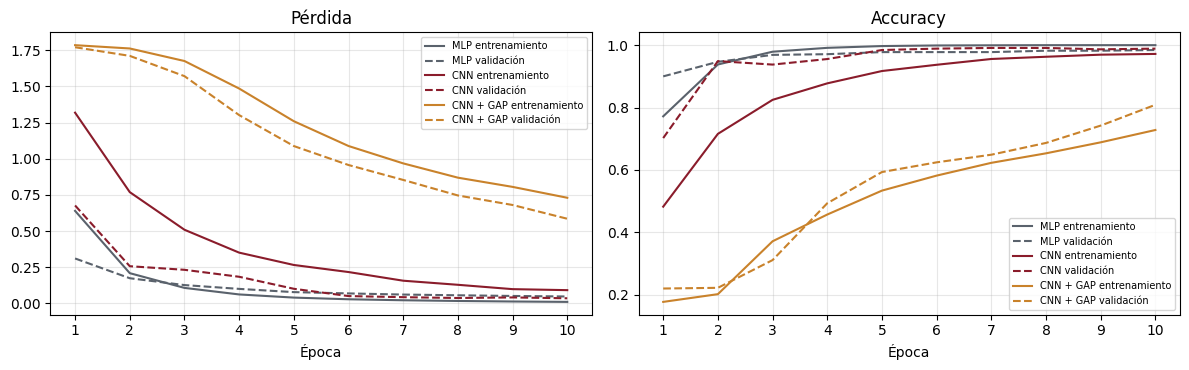

In [11]:
MODELOS = [("MLP", mlp, hist_mlp, "#5a626c"), ("CNN", cnn, hist_cnn, "#8a1c2b"), ("CNN + GAP", cnn_gap, hist_gap, "#c9822b")]
epocas = np.arange(1, EPOCAS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for nombre, _, h, color in MODELOS:
    axes[0].plot(epocas, h.history["loss"], color=color, label=f"{nombre} entrenamiento")
    axes[0].plot(epocas, h.history["val_loss"], color=color, ls="--", label=f"{nombre} validación")
    axes[1].plot(epocas, h.history["accuracy"], color=color, label=f"{nombre} entrenamiento")
    axes[1].plot(epocas, h.history["val_accuracy"], color=color, ls="--", label=f"{nombre} validación")
axes[0].set_title("Pérdida"); axes[1].set_title("Accuracy")
for a in axes:
    a.set_xlabel("Época"); a.set_xticks(epocas); a.legend(fontsize=7); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 9. Métricas en el conjunto de prueba

Para una compuerta *c*:
- **Accuracy:** fracción de todos los dibujos clasificados correctamente.
- **Precisión de c:** de los dibujos que la red dijo que eran *c*, cuántos lo eran. VP / (VP + FP).
- **Recall de c:** de los *c* reales, cuántos encontró la red. VP / (VP + FN).
- **F1 de c:** media armónica de precisión y recall; solo es alta si las dos lo son.
- **Matriz de confusión:** fila = compuerta real, columna = compuerta predicha. Lo que está fuera de la diagonal son errores.

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

predicciones = {}
for nombre, modelo, _, _ in MODELOS:
    prob = modelo.predict(X_test, verbose=0)
    predicciones[nombre] = (prob.argmax(axis=1), prob)
    print(f"===== {nombre} =====")
    print(classification_report(y_test, predicciones[nombre][0], target_names=CLASES, digits=3))

===== MLP =====
              precision    recall  f1-score   support

         AND      0.961     0.987     0.974        75
          OR      0.986     0.920     0.952        75
         NOT      1.000     1.000     1.000        75
        NAND      1.000     0.960     0.980        75
         NOR      0.962     1.000     0.980        75
         XOR      0.962     1.000     0.980        75

    accuracy                          0.978       450
   macro avg      0.978     0.978     0.978       450
weighted avg      0.978     0.978     0.978       450

===== CNN =====
              precision    recall  f1-score   support

         AND      0.949     1.000     0.974        75
          OR      1.000     0.987     0.993        75
         NOT      1.000     1.000     1.000        75
        NAND      1.000     0.920     0.958        75
         NOR      0.962     1.000     0.980        75
         XOR      1.000     1.000     1.000        75

    accuracy                          0.984  

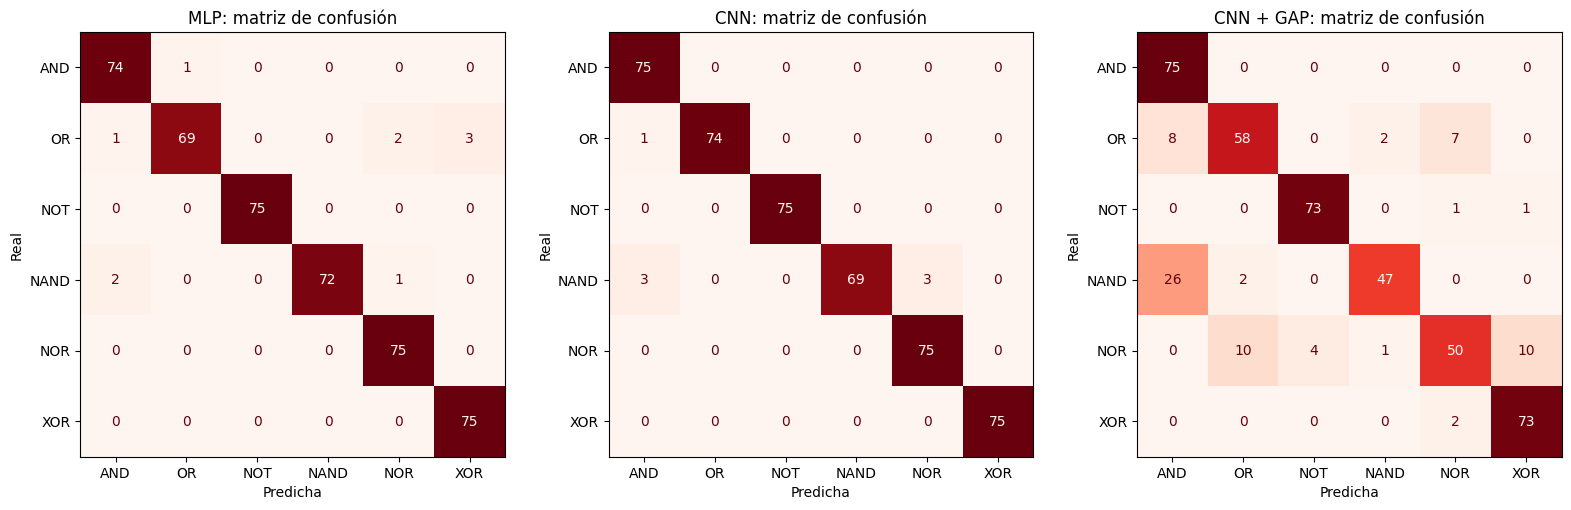

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for a, (nombre, _, _, _) in zip(axes, MODELOS):
    cm = confusion_matrix(y_test, predicciones[nombre][0], labels=range(len(CLASES)))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=a, cmap="Reds", colorbar=False)
    a.set_title(f"{nombre}: matriz de confusión"); a.set_xlabel("Predicha"); a.set_ylabel("Real")
plt.tight_layout(); plt.show()

## 10. Parejas difíciles y errores

Algunas compuertas se diferencian solo por un detalle pequeño:
- **AND / NAND** y **OR / NOR:** la burbuja a la salida.
- **OR / XOR:** el arco extra detrás de la figura.
- **AND / OR:** la parte trasera recta o curva.

Se mide qué porcentaje de los dibujos de una compuerta se confundió con la otra, en ambos sentidos.

In [14]:
PAREJAS = [("AND", "NAND"), ("OR", "NOR"), ("OR", "XOR"), ("AND", "OR")]

def confusion_parejas(y_real, y_pred):
    cm = confusion_matrix(y_real, y_pred, labels=range(len(CLASES)))
    filas = []
    for a, b in PAREJAS:
        ia, ib = CLASES.index(a), CLASES.index(b)
        filas.append((f"{a} → {b}", 100 * cm[ia, ib] / max(1, cm[ia].sum())))
        filas.append((f"{b} → {a}", 100 * cm[ib, ia] / max(1, cm[ib].sum())))
    return filas

tablas = [confusion_parejas(y_test, predicciones[n][0]) for n, _, _, _ in MODELOS]
print(f"{'Confusión':<14}" + "".join(f"{n:>11}" for n, _, _, _ in MODELOS))
for k, (texto, _) in enumerate(tablas[0]):
    print(f"{texto:<14}" + "".join(f"{t[k][1]:>10.1f}%" for t in tablas))

Confusión             MLP        CNN  CNN + GAP
AND → NAND           0.0%       0.0%       0.0%
NAND → AND           2.7%       4.0%      34.7%
OR → NOR             2.7%       0.0%       9.3%
NOR → OR             0.0%       0.0%      13.3%
OR → XOR             4.0%       0.0%       0.0%
XOR → OR             0.0%       0.0%       0.0%
AND → OR             1.3%       0.0%       0.0%
OR → AND             1.3%       1.3%      10.7%


### Dibujos que la CNN clasificó mal

7 errores de 450 dibujos de prueba


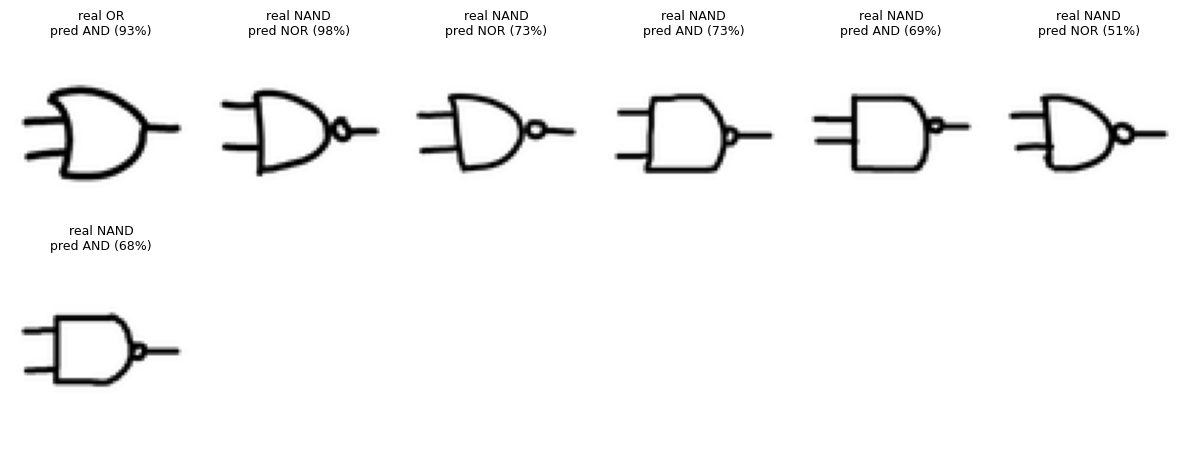

In [15]:
pred_cnn, prob_cnn = predicciones["CNN"]
errores = np.where(pred_cnn != y_test)[0]
print(f"{len(errores)} errores de {len(y_test)} dibujos de prueba")
n = min(18, len(errores))
if n:
    cols = 6; filas = int(np.ceil(n / cols))
    fig, axes = plt.subplots(filas, cols, figsize=(12, 2.3 * filas), squeeze=False)
    for k, a in enumerate(axes.flat):
        a.axis("off")
        if k < n:
            i = errores[k]
            a.imshow(X_test[i, ..., 0], cmap="gray_r")
            a.set_title(f"real {CLASES[y_test[i]]}\npred {CLASES[pred_cnn[i]]} ({prob_cnn[i].max():.0%})", fontsize=9)
    plt.tight_layout(); plt.show()

## 11. Class Activation Maps (CAM)

**Clase 3 y notebook del profesor (CAM con ResNet50).** Con GAP, el puntaje de cada compuerta es una suma ponderada de los promedios de los 64 mapas de la última convolución. Si esa misma suma ponderada se hace con los mapas completos (antes de promediar), se obtiene el **Class Activation Map**: un mapa de calor que marca las zonas del dibujo que más empujaron hacia esa respuesta ([Zhou et al., 2016](https://arxiv.org/abs/1512.04150)). ResNet50 permite CAM por la misma razón: también termina en GAP y una capa densa.

Para un dibujo y una compuerta *c*:
1. Se obtienen los 64 mapas de la última convolución (12×12 cada uno).
2. Cada mapa se multiplica por el peso que la capa de salida le da a *c* y se suman: `CAM = Σ_k w[k, c] · mapa_k`.
3. Se dejan solo los valores positivos, se escala de 0 a 1 y se agranda a 64×64 para ponerlo encima del dibujo.

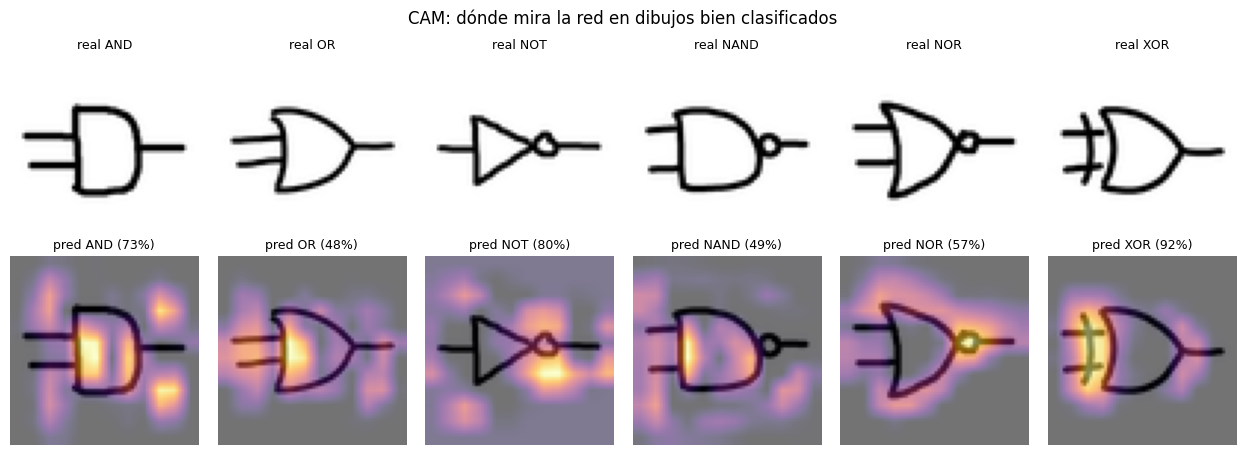

La CNN con GAP falló 74 dibujos de prueba


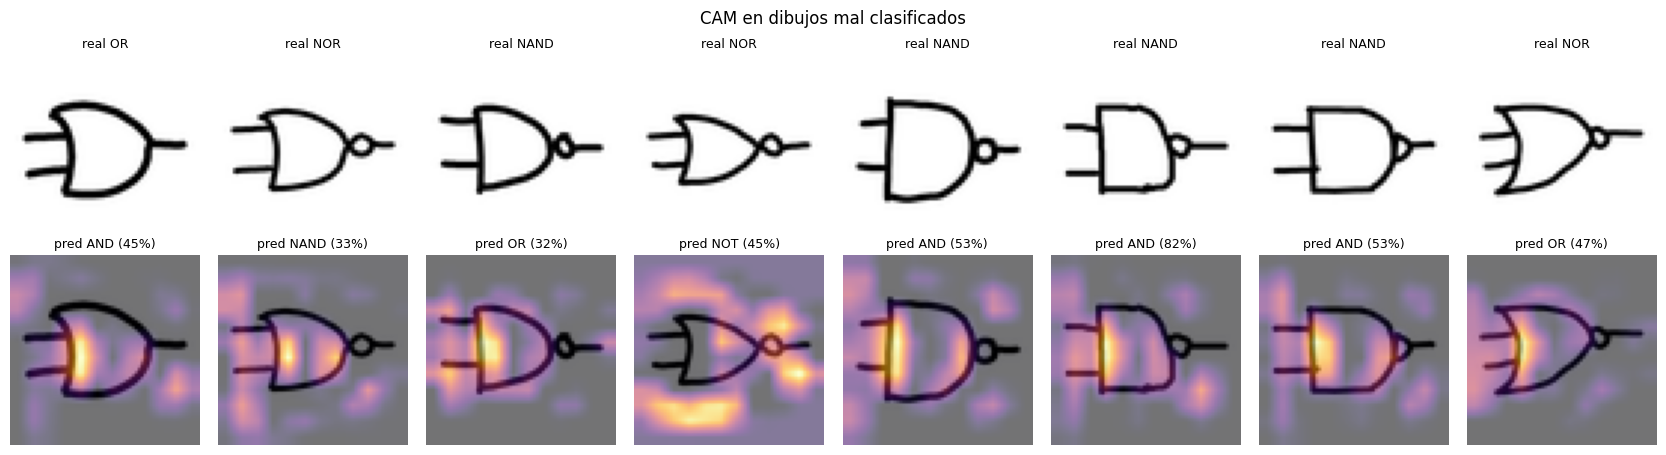

In [16]:
# Modelo que devuelve los mapas de la última convolución y las probabilidades.
# Se arma pasando una entrada nueva por las capas entrenadas, sin las capas de aumento de datos.
entrada = keras.Input((TAM, TAM, 1))
x = entrada
for capa in cnn_gap.layers:
    if capa.name == "aumento_de_datos":
        continue
    x = capa(x)
    if capa.name == "ultima_conv":
        mapas_conv = x
extractor = keras.Model(entrada, [mapas_conv, x])
pesos_salida = cnn_gap.get_layer("salida").get_weights()[0]   # (64 mapas, una columna por compuerta)

def mapa_cam(imagen):
    mapas, prob = extractor.predict(imagen[None], verbose=0)
    clase = int(prob[0].argmax())
    cam = np.maximum(mapas[0] @ pesos_salida[:, clase], 0)
    cam = cam / (cam.max() + 1e-8)
    cam = np.asarray(Image.fromarray(cam.astype(np.float32)).resize((TAM, TAM), Image.Resampling.BILINEAR))
    return cam, clase, prob[0]

def mostrar_cams(indices, titulo):
    fig, axes = plt.subplots(2, len(indices), figsize=(2.1 * len(indices), 4.6), squeeze=False)
    for k, i in enumerate(indices):
        cam, clase, prob = mapa_cam(X_test[i])
        axes[0, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[0, k].set_title(f"real {CLASES[y_test[i]]}", fontsize=9)
        axes[1, k].imshow(X_test[i, ..., 0], cmap="gray_r")
        axes[1, k].imshow(cam, cmap="inferno", alpha=0.55)
        axes[1, k].set_title(f"pred {CLASES[clase]} ({prob[clase]:.0%})", fontsize=9)
        for a in axes[:, k]:
            a.axis("off")
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

pred_gap = predicciones["CNN + GAP"][0]
rng = np.random.default_rng(1)
ejemplos = []
for c in range(len(CLASES)):
    bien = np.where((y_test == c) & (pred_gap == y_test))[0]
    if len(bien):
        ejemplos.append(rng.choice(bien))
mostrar_cams(ejemplos, "CAM: dónde mira la red en dibujos bien clasificados")

fallados = np.where(pred_gap != y_test)[0]
print(f"La CNN con GAP falló {len(fallados)} dibujos de prueba")
if len(fallados):
    mostrar_cams(list(fallados[:8]), "CAM en dibujos mal clasificados")

## 12. Resumen y conclusiones

In [17]:
print(f"Dibujos: {len(y)} ({len(idx_train)} entrenamiento, {len(idx_val)} validación, {len(idx_test)} prueba)")
print(f"Épocas: {EPOCAS} · aumento de datos en las CNN: {'sí' if USAR_AUMENTO else 'no'}\n")
print(f"{'Modelo':<11}{'Accuracy':>10}{'F1 macro':>10}{'Errores':>9}{'Parámetros':>12}")
for nombre, modelo, _, _ in MODELOS:
    pred = predicciones[nombre][0]
    print(f"{nombre:<11}{accuracy_score(y_test, pred):>10.1%}{f1_score(y_test, pred, average='macro'):>10.3f}"
          f"{int((pred != y_test).sum()):>9}{modelo.count_params():>12,}")

Dibujos: 3000 (2100 entrenamiento, 450 validación, 450 prueba)
Épocas: 10 · aumento de datos en las CNN: sí

Modelo       Accuracy  F1 macro  Errores  Parámetros
MLP             97.8%     0.978       10     525,190
CNN             98.4%     0.984        7      78,598
CNN + GAP       83.6%     0.831       74      23,686


Completar con los números de la celda anterior:

1. **MLP contra CNN (clase 1):** ¿cuánto mejora la CNN y con cuántos parámetros menos? ¿En qué parejas se confunde más el MLP?
2. **Parejas difíciles:** ¿se confunden más las que solo cambian en la burbuja (AND/NAND, OR/NOR), en el arco (OR/XOR) o en la trasera (AND/OR)?
3. **GAP (clase 3):** ¿cuánta precisión se pierde (o gana) con unas 3.3 veces menos parámetros?
4. **CAM:** ¿la red mira la burbuja, el arco y la parte trasera? ¿Qué miró en los dibujos que falló?
5. **Aumento de datos:** ¿cambia el resultado con `USAR_AUMENTO = False`?

## Exportar los pesos de la CNN

La página web del repositorio repite con numpy las capas de su propia CNN (`prediccion.py`). Esta CNN tiene otra arquitectura, así que sus pesos se guardan con otro nombre (`pesos_cnn_curso.npz`) para no reemplazar los de la página. Para usarlos en la página hay que adaptar antes `prediccion.py`.

In [18]:
pesos = [w for capa in cnn.layers if isinstance(capa, (layers.Conv2D, layers.Dense)) for w in capa.get_weights()]
np.savez("pesos_cnn_curso.npz", *pesos)
print(f"Guardado pesos_cnn_curso.npz: {len(pesos)} arreglos, {sum(w.size for w in pesos):,} pesos")

Guardado pesos_cnn_curso.npz: 8 arreglos, 78,598 pesos
